In [1]:
# Random Forest Classification – Glass Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier,
                              AdaBoostClassifier, GradientBoostingClassifier)
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight
import warnings
warnings.filterwarnings('ignore')

In [3]:
# TASK 1 – EXPLORATORY DATA ANALYSIS (EDA)

In [4]:
import pandas as pd
df = pd.read_excel('glass.xlsx', sheet_name='glass')

print("=" * 65)
print("TASK 1 – EXPLORATORY DATA ANALYSIS")
print("=" * 65)
print(f"\nDataset Shape : {df.shape}  ({df.shape[0]} rows, {df.shape[1]} columns)")
print("\nFirst 5 Rows:")
print(df.head())
print("\nData Types:")
print(df.dtypes)
print("\nStatistical Summary:")
print(df.describe().round(4))
print("\nMissing Values:")
print(df.isnull().sum())
print("\nTarget Class Distribution:")
type_labels = {1: 'Build Win Float', 2: 'Build Win Non-Float',
               3: 'Vehicle Win Float', 5: 'Containers',
               6: 'Tableware', 7: 'Headlamps'}
print(df['Type'].value_counts().sort_index()
      .rename(index=type_labels).to_string())

print("\nOutlier Detection (IQR Method):")
features = [c for c in df.columns if c != 'Type']
for col in features:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    n_out = ((df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)).sum()
    print(f"  {col:6s}: {n_out:2d} outliers")



TASK 1 – EXPLORATORY DATA ANALYSIS

Dataset Shape : (214, 10)  (214 rows, 10 columns)

First 5 Rows:
        RI     Na    Mg    Al     Si     K    Ca   Ba   Fe  Type
0  1.52101  13.64  4.49  1.10  71.78  0.06  8.75  0.0  0.0     1
1  1.51761  13.89  3.60  1.36  72.73  0.48  7.83  0.0  0.0     1
2  1.51618  13.53  3.55  1.54  72.99  0.39  7.78  0.0  0.0     1
3  1.51766  13.21  3.69  1.29  72.61  0.57  8.22  0.0  0.0     1
4  1.51742  13.27  3.62  1.24  73.08  0.55  8.07  0.0  0.0     1

Data Types:
RI      float64
Na      float64
Mg      float64
Al      float64
Si      float64
K       float64
Ca      float64
Ba      float64
Fe      float64
Type      int64
dtype: object

Statistical Summary:
             RI        Na        Mg        Al        Si         K        Ca  \
count  214.0000  214.0000  214.0000  214.0000  214.0000  214.0000  214.0000   
mean     1.5184   13.4079    2.6845    1.4449   72.6509    0.4971    8.9570   
std      0.0030    0.8166    1.4424    0.4993    0.7745    0.65

In [5]:
# TASK 2 – DATA VISUALIZATION

In [6]:
print("\n" + "=" * 65)
print("TASK 2 – DATA VISUALIZATION")
print("=" * 65)


TASK 2 – DATA VISUALIZATION


In [7]:
# Plot 1: Class Distribution
fig, ax = plt.subplots(figsize=(8, 4))
vc = df['Type'].value_counts().sort_index()
short_labels = ['BW-Float', 'BW-Non-Float', 'VW-Float',
                'Containers', 'Tableware', 'Headlamps']
bars = ax.bar(short_labels, vc.values, color='steelblue', edgecolor='black')
for bar, val in zip(bars, vc.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            str(val), ha='center', fontsize=10, fontweight='bold')
ax.set_title('Class Distribution – Glass Types', fontweight='bold', fontsize=13)
ax.set_ylabel('Count'); ax.set_xlabel('Glass Type')
plt.xticks(rotation=20, ha='right')
plt.tight_layout(); plt.savefig('plot1_class_distribution.png', dpi=130); plt.show()

NameError: name 'plt' is not defined

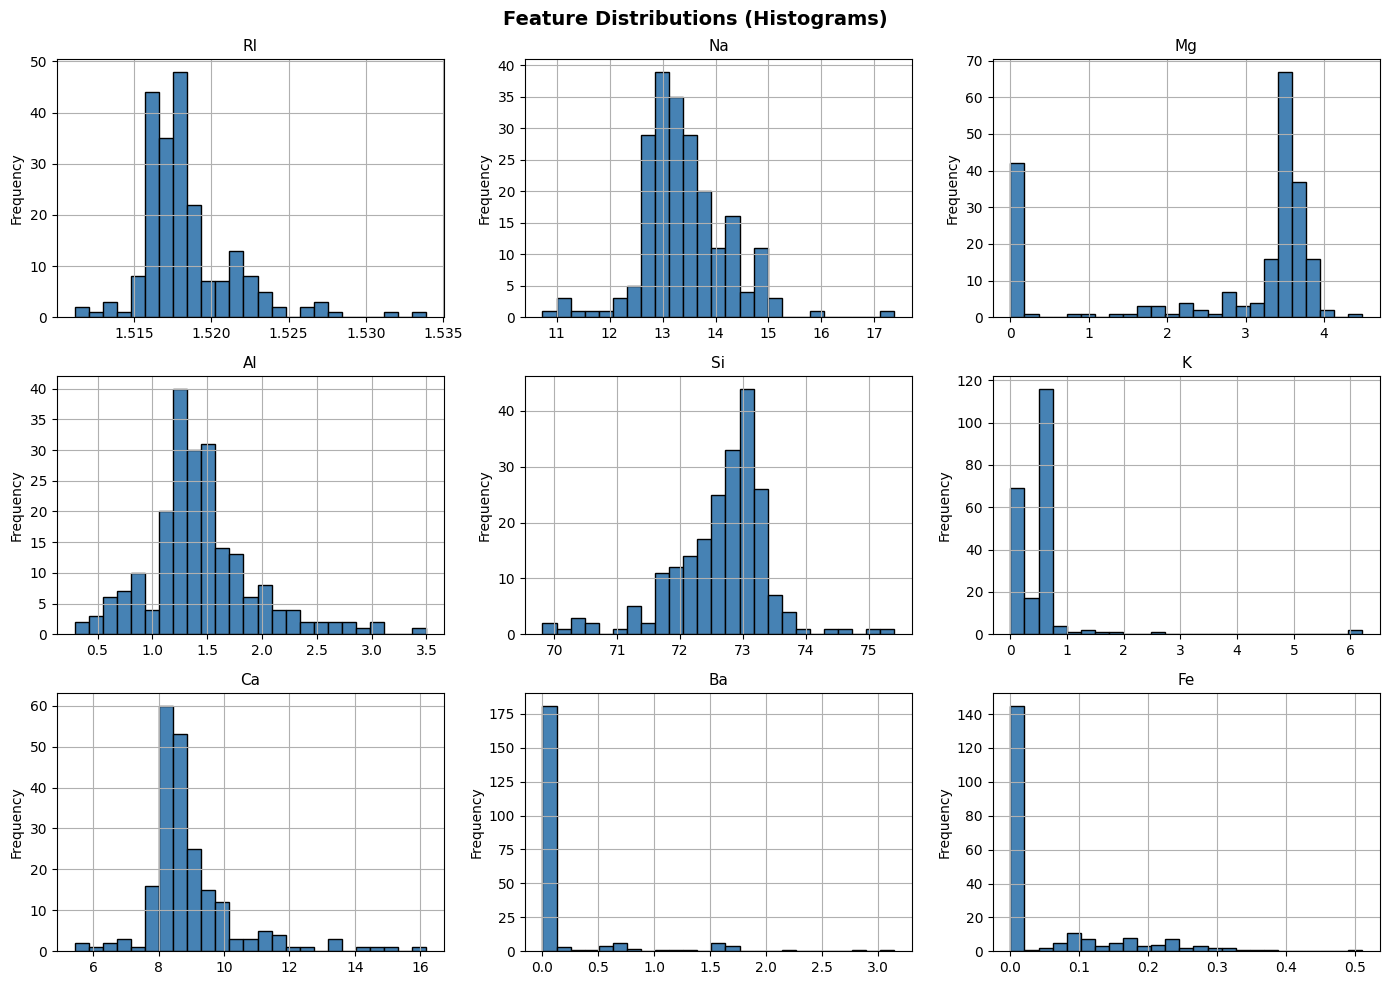

In [9]:
# Plot 2: Histograms
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for i, col in enumerate(features):
    ax = axes[i // 3][i % 3]
    df[col].hist(bins=25, ax=ax, color='steelblue', edgecolor='black')
    ax.set_title(col, fontsize=11); ax.set_ylabel('Frequency')
plt.suptitle('Feature Distributions (Histograms)', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('plot2_histograms.png', dpi=130); plt.show()

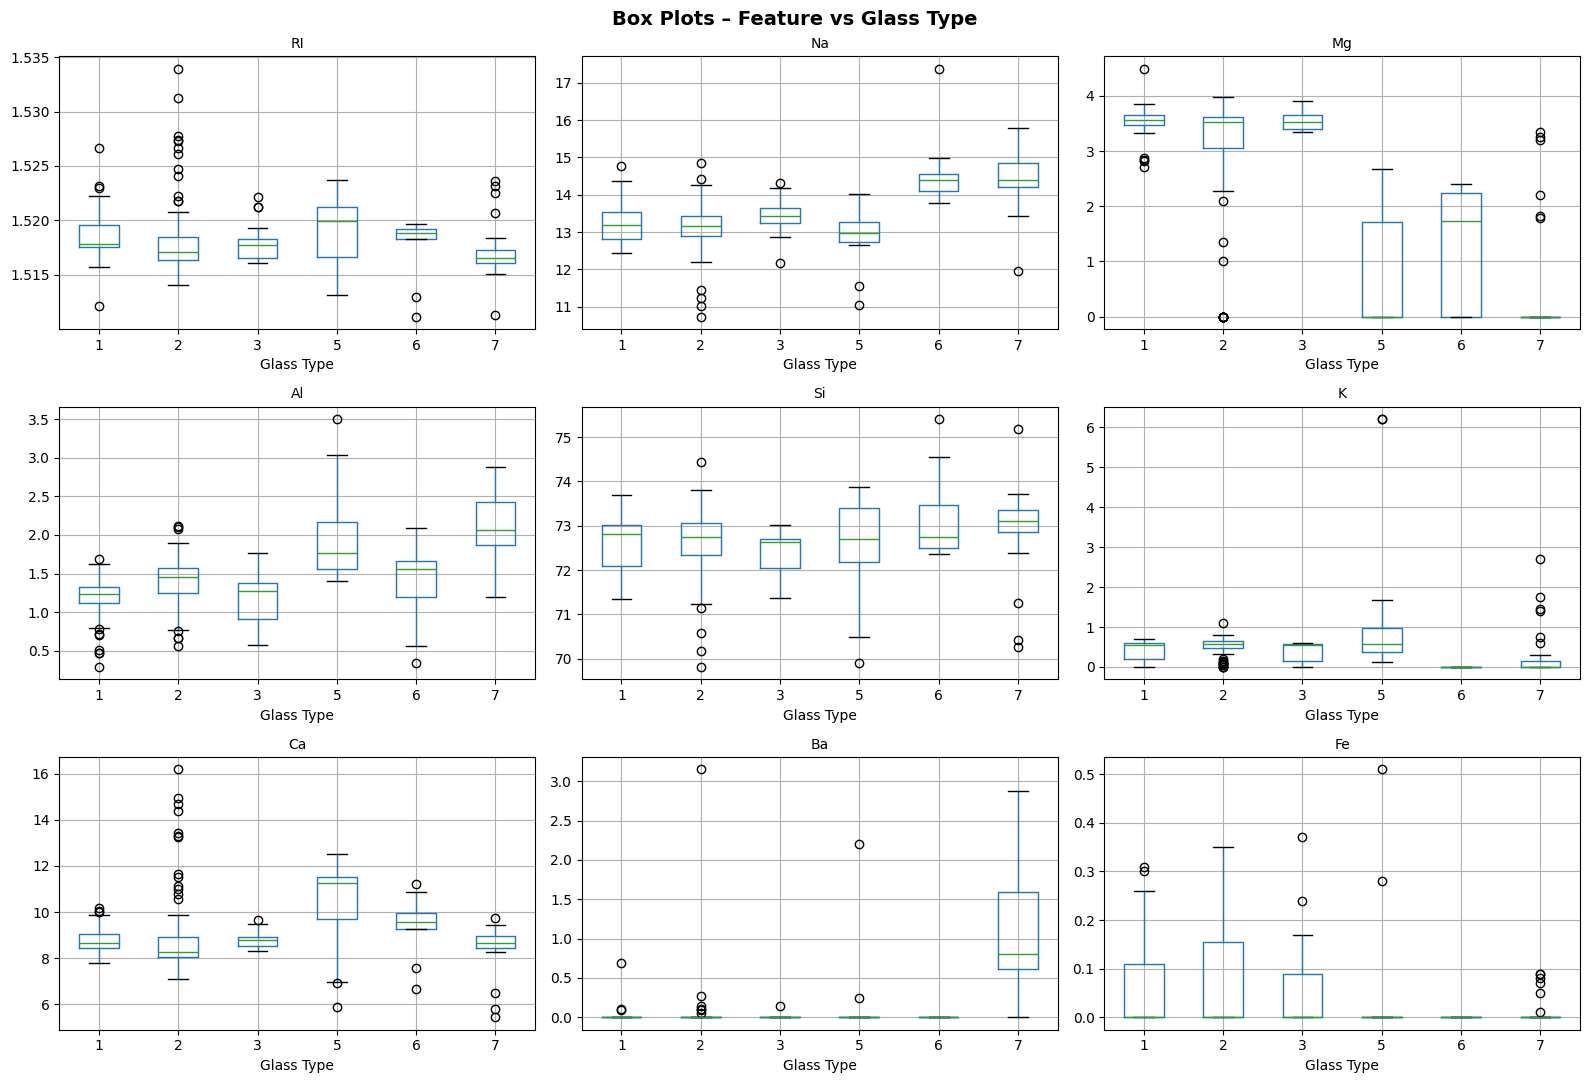

In [10]:
# Plot 3: Box Plots by Glass Type
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for i, col in enumerate(features):
    ax = axes[i // 3][i % 3]
    df.boxplot(column=col, by='Type', ax=ax)
    ax.set_title(col, fontsize=10); ax.set_xlabel('Glass Type')
plt.suptitle('Box Plots – Feature vs Glass Type', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('plot3_boxplots.png', dpi=130); plt.show()

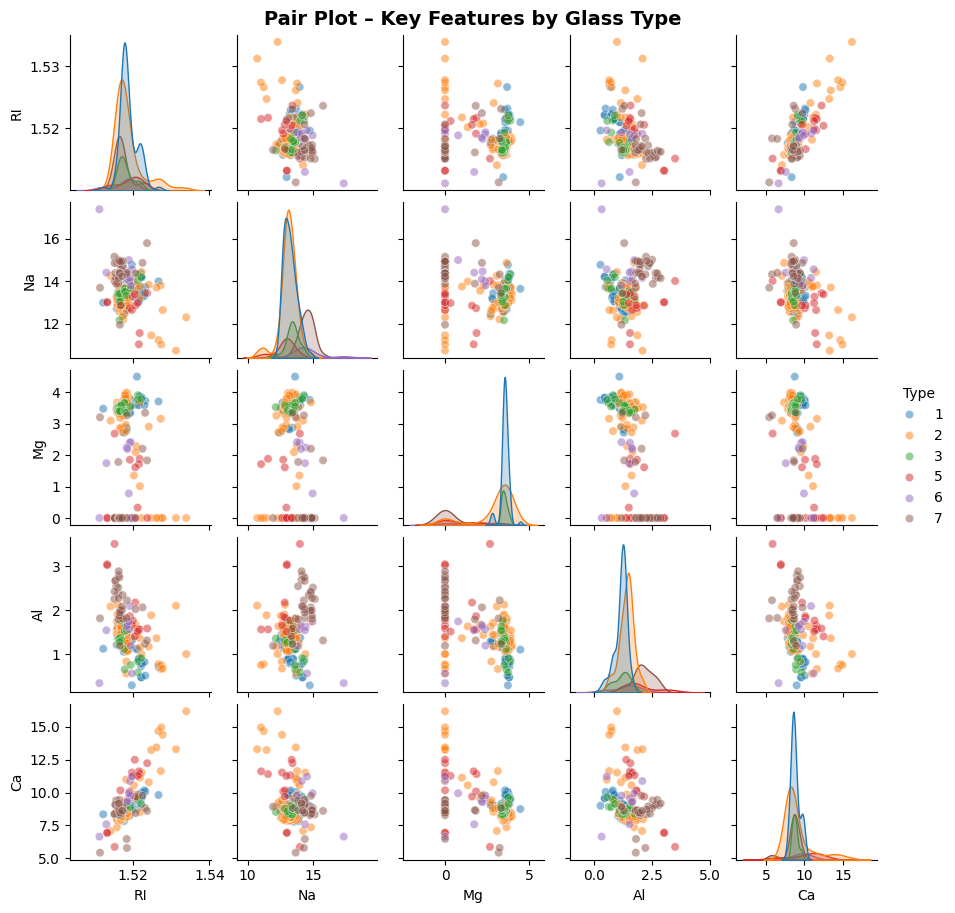

In [12]:
# Plot 4: Pair Plot (selected features)
import seaborn as sns
import matplotlib.pyplot as plt
pair_df = df[['RI', 'Na', 'Mg', 'Al', 'Ca', 'Type']].copy()
pair_df['Type'] = pair_df['Type'].astype(str)
g = sns.pairplot(pair_df, hue='Type', diag_kind='kde',
                 plot_kws={'alpha': 0.5}, height=1.8)
g.fig.suptitle('Pair Plot – Key Features by Glass Type', y=1.01,
               fontsize=14, fontweight='bold')
plt.savefig('plot4_pairplot.png', dpi=100, bbox_inches='tight'); plt.show()

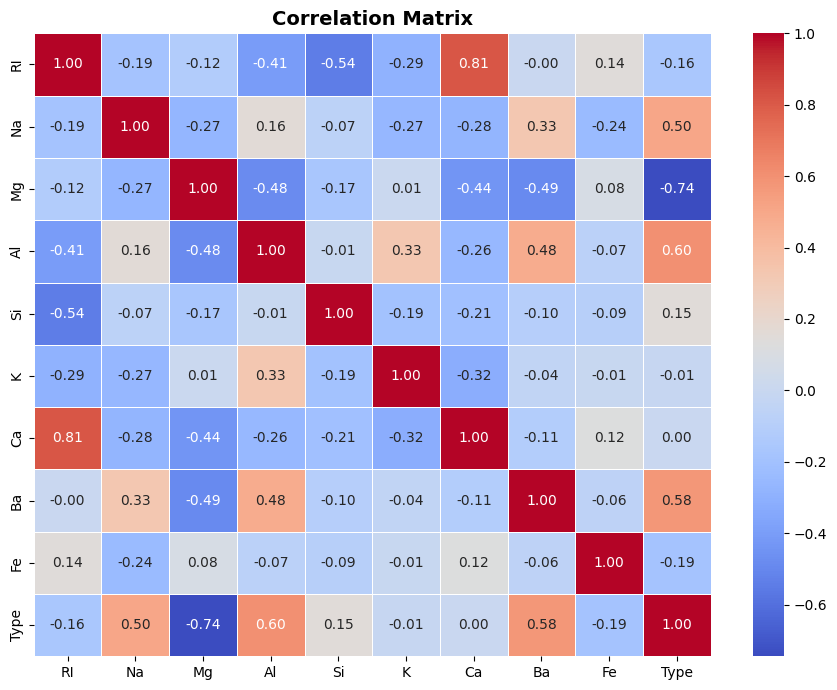

Observations:
  - RI is strongly correlated with Ca (+0.81) and negatively with Si (-0.54)
  - Ba and Al have high discriminative power for glass types
  - Mg shows low values for non-window glass (containers/tableware/headlamps)


In [13]:
# Plot 5: Correlation Heatmap
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm',
            ax=ax, linewidths=0.5)
ax.set_title('Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('plot5_correlation.png', dpi=130); plt.show()

print("Observations:")
print("  - RI is strongly correlated with Ca (+0.81) and negatively with Si (-0.54)")
print("  - Ba and Al have high discriminative power for glass types")
print("  - Mg shows low values for non-window glass (containers/tableware/headlamps)")


In [14]:
# TASK 3 – DATA PREPROCESSING

In [15]:
# 3a. Missing values
print(f"\nMissing values: {df.isnull().sum().sum()} → No imputation needed")


Missing values: 0 → No imputation needed


In [16]:
# 3b. Categorical variables
print("No categorical variables. All features are already numerical.")

No categorical variables. All features are already numerical.


In [17]:
# 3c. Feature Scaling (StandardScaler)
X = df[features]
y = df['Type']

In [19]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=features)
print("\nAfter StandardScaler (mean≈0, std≈1):")
print(X_scaled.describe().round(3).loc[['mean', 'std']])



After StandardScaler (mean≈0, std≈1):
         RI     Na     Mg     Al     Si      K     Ca     Ba     Fe
mean -0.000  0.000 -0.000 -0.000  0.000  0.000 -0.000 -0.000 -0.000
std   1.002  1.002  1.002  1.002  1.002  1.002  1.002  1.002  1.002


In [58]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# 3d. Imbalance Handling - Class Weights
print("\nHandling Class Imbalance:")
print(" Strategy: class_weight='balanced' in RandomForestClassifier")
print(" This assigns higher weight to minority classes during training.")

# Ensure 'y' is defined (your target labels)
classes = np.unique(y)

# Correct call using keyword arguments (class_weight='balanced')
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y)

# Create a dictionary for the weights
cw = dict(zip(classes, weights))

# Print the weights for each class
for cls, wt in cw.items():
    # Ensure 'type_labels' is defined elsewhere in your notebook
    label = type_labels[cls]
    print(f" Class {cls} ({label[:18]:18s}): weight = {wt:.3f}")


Handling Class Imbalance:
 Strategy: class_weight='balanced' in RandomForestClassifier
 This assigns higher weight to minority classes during training.
 Class 1 (Build Win Float   ): weight = 0.510
 Class 2 (Build Win Non-Floa): weight = 0.469
 Class 3 (Vehicle Win Float ): weight = 2.098
 Class 5 (Containers        ): weight = 2.744
 Class 6 (Tableware         ): weight = 3.963
 Class 7 (Headlamps         ): weight = 1.230


In [22]:
# 3d. Imbalance Handling – Class Weights
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
print("\nHandling Class Imbalance:")
print("  Strategy: class_weight='balanced' in RandomForestClassifier")
print("  This assigns higher weight to minority classes during training.")
classes = np.unique(y)
weights = compute_class_weight('balanced', classes=classes, y=y)
cw = dict(zip(classes, weights))
for cls, wt in cw.items():
    print(f"    Class {cls} ({type_labels[cls][:18]:18s}): weight = {wt:.3f}")


Handling Class Imbalance:
  Strategy: class_weight='balanced' in RandomForestClassifier
  This assigns higher weight to minority classes during training.
    Class 1 (Build Win Float   ): weight = 0.510
    Class 2 (Build Win Non-Floa): weight = 0.469
    Class 3 (Vehicle Win Float ): weight = 2.098
    Class 5 (Containers        ): weight = 2.744
    Class 6 (Tableware         ): weight = 3.963
    Class 7 (Headlamps         ): weight = 1.230


In [23]:
# TASK 4 – RANDOM FOREST MODEL

In [57]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# 1. Data Splitting
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train samples: {X_train.shape[0]} | Test samples: {X_test.shape[0]}")

# 2. Model Initialization and Training
rf = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced', n_jobs=-1)
rf.fit(X_train, y_train)

# 3. Predictions and Cross-Validation
y_pred_rf = rf.predict(X_test)
cv_rf = cross_val_score(rf, X_scaled, y, cv=5, scoring='accuracy')

# 4. Performance Metrics
print("\n" + "="*30)
print("--- Random Forest Performance ---")
print(f"Accuracy    : {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision   : {precision_score(y_test, y_pred_rf, average='weighted'):.4f}")
print(f"Recall      : {recall_score(y_test, y_pred_rf, average='weighted'):.4f}")
print(f"F1-Score    : {f1_score(y_test, y_pred_rf, average='weighted'):.4f}")

# Fixed the syntax error/special character issue here:
print(f"5-Fold CV   : {cv_rf.mean():.4f} +/- {cv_rf.std():.4f}")

print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

Train samples: 171 | Test samples: 43

--- Random Forest Performance ---
Accuracy    : 0.8140
Precision   : 0.8283
Recall      : 0.8140
F1-Score    : 0.8147
5-Fold CV   : 0.6919 +/- 0.0457

Classification Report:
               precision    recall  f1-score   support

           1       0.75      0.86      0.80        14
           2       0.79      0.73      0.76        15
           3       1.00      0.67      0.80         3
           5       1.00      1.00      1.00         3
           6       0.67      1.00      0.80         2
           7       1.00      0.83      0.91         6

    accuracy                           0.81        43
   macro avg       0.87      0.85      0.84        43
weighted avg       0.83      0.81      0.81        43



In [25]:
print("\n" + "=" * 65)
print("TASK 4 – RANDOM FOREST CLASSIFICATION")
print("=" * 65)

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y)
print(f"\nTrain samples : {X_train.shape[0]}  |  Test samples : {X_test.shape[0]}")

rf = RandomForestClassifier(n_estimators=200, random_state=42,
                            class_weight='balanced', n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
cv_rf = cross_val_score(rf, X_scaled, y, cv=5, scoring='accuracy')

print("\n--- Random Forest Performance ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_rf, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_rf, average='weighted'):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_rf, average='weighted'):.4f}")
print(f"5-Fold CV : {cv_rf.mean():.4f} \u00b1 {cv_rf.std():.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


TASK 4 – RANDOM FOREST CLASSIFICATION

Train samples : 171  |  Test samples : 43

--- Random Forest Performance ---
Accuracy  : 0.8140
Precision : 0.8283
Recall    : 0.8140
F1-Score  : 0.8147
5-Fold CV : 0.6919 ± 0.0457

Classification Report:
              precision    recall  f1-score   support

           1       0.75      0.86      0.80        14
           2       0.79      0.73      0.76        15
           3       1.00      0.67      0.80         3
           5       1.00      1.00      1.00         3
           6       0.67      1.00      0.80         2
           7       1.00      0.83      0.91         6

    accuracy                           0.81        43
   macro avg       0.87      0.85      0.84        43
weighted avg       0.83      0.81      0.81        43



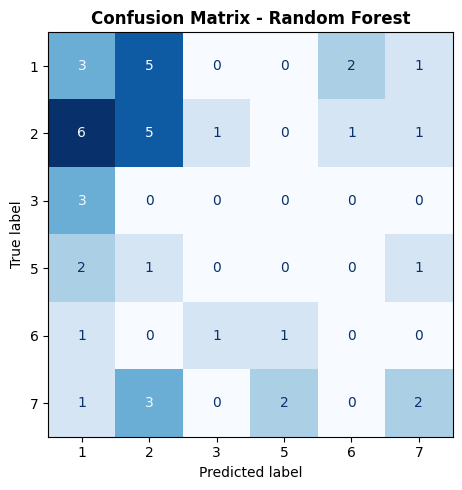

In [56]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Initialize the plot
fig, ax = plt.subplots(figsize=(6, 5))

# 2. Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred_rf, labels=classes)

# 3. Create the display
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(ax=ax, colorbar=False, cmap='Blues')

# 4. Final touches
ax.set_title('Confusion Matrix - Random Forest', fontweight='bold')
plt.tight_layout()
plt.savefig('plot_rf_confusion.png', dpi=130)
plt.show()

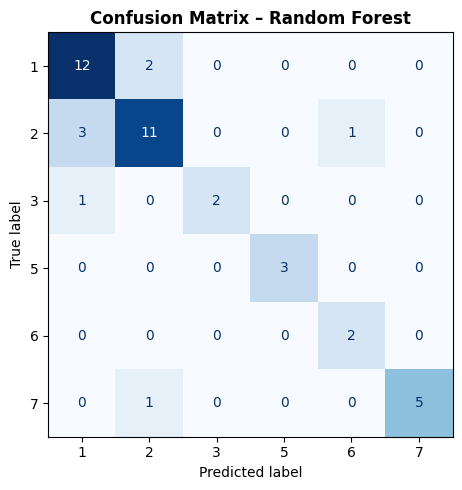

In [27]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_rf, labels=classes)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(
    ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Confusion Matrix – Random Forest', fontweight='bold')
plt.tight_layout(); plt.savefig('plot6_rf_confusion.png', dpi=130); plt.show()

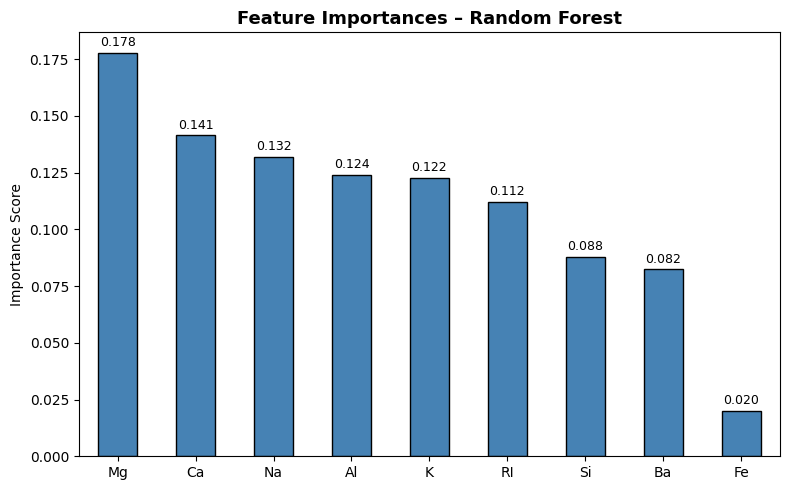


Top Features by Importance:
Mg    0.1779
Ca    0.1414
Na    0.1318
Al    0.1239
K     0.1225
RI    0.1122
Si    0.0879
Ba    0.0824
Fe    0.0201


In [28]:
# Feature Importances
feat_imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
feat_imp.plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Feature Importances – Random Forest', fontweight='bold', fontsize=13)
ax.set_ylabel('Importance Score')
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
            f'{bar.get_height():.3f}', ha='center', fontsize=9)
plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig('plot7_feature_importance.png', dpi=130); plt.show()

print("\nTop Features by Importance:")
print(feat_imp.round(4).to_string())

In [29]:
# TASK 5 – BAGGING AND BOOSTING

In [30]:
print("\n" + "=" * 65)
print("TASK 5 – BAGGING AND BOOSTING")
print("=" * 65)


TASK 5 – BAGGING AND BOOSTING


In [53]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
# note: verify if you meant f1_score

# 1. Split your data first (Make sure X_scaled and y are already defined above)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# 2. Define and train the Bagging Classifier
bag = BaggingClassifier(estimator=DecisionTreeClassifier(),
                        n_estimators=100,
                        random_state=42,
                        n_jobs=-1)

bag.fit(X_train, y_train)

# 3. Predict and evaluate
y_pred_bag = bag.predict(X_test)
cv_bag = cross_val_score(bag, X_scaled, y, cv=5, scoring='accuracy')

# 4. Print metrics
print("\n--- Bagging Classifier ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_bag):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_bag, average='weighted'):.4f}") # fixed typo from your image: f1_score instead of f1_score() inside string
print(f"5-Fold CV : {cv_bag.mean():.4f} +/- {cv_bag.std():.4f}")


--- Bagging Classifier ---
Accuracy  : 0.8605
Precision : 0.8600
Recall    : 0.8605
F1-Score  : 0.8514
5-Fold CV : 0.6405 +/- 0.0841


In [50]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ── Bagging ──────────────────────────────────────────────────────────────────
bag = BaggingClassifier(estimator=DecisionTreeClassifier(),
                        n_estimators=100, random_state=42, n_jobs=-1)
bag.fit(X_train, y_train)
y_pred_bag = bag.predict(X_test)
cv_bag = cross_val_score(bag, X_scaled, y, cv=5, scoring='accuracy')

print("\n--- Bagging Classifier ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_bag):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"5-Fold CV : {cv_bag.mean():.4f} \u00b1 {cv_bag.std():.4f}")


--- Bagging Classifier ---
Accuracy  : 0.7907
Precision : 0.7946
Recall    : 0.7907
F1-Score  : 0.7889
5-Fold CV : 0.6405 ± 0.0841


In [49]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ── Bagging ──────────────────────────────────────────────────────────────────
bag = BaggingClassifier(estimator=DecisionTreeClassifier(),
                        n_estimators=100, random_state=42, n_jobs=-1)
bag.fit(X_train, y_train)
y_pred_bag = bag.predict(X_test)
cv_bag = cross_val_score(bag, X_scaled, y, cv=5, scoring='accuracy')

print("\n--- Bagging Classifier ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_bag):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"5-Fold CV : {cv_bag.mean():.4f} \u00b1 {cv_bag.std():.4f}")


--- Bagging Classifier ---
Accuracy  : 0.7907
Precision : 0.7946
Recall    : 0.7907
F1-Score  : 0.7889
5-Fold CV : 0.6405 ± 0.0841


In [48]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ── Bagging ──────────────────────────────────────────────────────────────────
bag = BaggingClassifier(estimator=DecisionTreeClassifier(),
                        n_estimators=100, random_state=42, n_jobs=-1)
bag.fit(X_train, y_train)
y_pred_bag = bag.predict(X_test)
cv_bag = cross_val_score(bag, X_scaled, y, cv=5, scoring='accuracy')

print("\n--- Bagging Classifier ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_bag):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"5-Fold CV : {cv_bag.mean():.4f} \u00b1 {cv_bag.std():.4f}")


--- Bagging Classifier ---
Accuracy  : 0.7907
Precision : 0.7946
Recall    : 0.7907
F1-Score  : 0.7889
5-Fold CV : 0.6405 ± 0.0841


In [47]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ── Bagging ──────────────────────────────────────────────────────────────────
bag = BaggingClassifier(estimator=DecisionTreeClassifier(),
                        n_estimators=100, random_state=42, n_jobs=-1)
bag.fit(X_train, y_train)
y_pred_bag = bag.predict(X_test)
cv_bag = cross_val_score(bag, X_scaled, y, cv=5, scoring='accuracy')

print("\n--- Bagging Classifier ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_bag):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"5-Fold CV : {cv_bag.mean():.4f} \u00b1 {cv_bag.std():.4f}")


--- Bagging Classifier ---
Accuracy  : 0.7907
Precision : 0.7946
Recall    : 0.7907
F1-Score  : 0.7889
5-Fold CV : 0.6405 ± 0.0841


In [46]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ── Bagging ──────────────────────────────────────────────────────────────────
bag = BaggingClassifier(estimator=DecisionTreeClassifier(),
                        n_estimators=100, random_state=42, n_jobs=-1)
bag.fit(X_train, y_train)
y_pred_bag = bag.predict(X_test)
cv_bag = cross_val_score(bag, X_scaled, y, cv=5, scoring='accuracy')

print("\n--- Bagging Classifier ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_bag):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"5-Fold CV : {cv_bag.mean():.4f} \u00b1 {cv_bag.std():.4f}")


--- Bagging Classifier ---
Accuracy  : 0.7907
Precision : 0.7946
Recall    : 0.7907
F1-Score  : 0.7889
5-Fold CV : 0.6405 ± 0.0841


In [45]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ── Bagging ──────────────────────────────────────────────────────────────────
bag = BaggingClassifier(estimator=DecisionTreeClassifier(),
                        n_estimators=100, random_state=42, n_jobs=-1)
bag.fit(X_train, y_train)
y_pred_bag = bag.predict(X_test)
cv_bag = cross_val_score(bag, X_scaled, y, cv=5, scoring='accuracy')

print("\n--- Bagging Classifier ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_bag):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"5-Fold CV : {cv_bag.mean():.4f} \u00b1 {cv_bag.std():.4f}")


--- Bagging Classifier ---
Accuracy  : 0.7907
Precision : 0.7946
Recall    : 0.7907
F1-Score  : 0.7889
5-Fold CV : 0.6405 ± 0.0841


In [32]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ── Bagging ──────────────────────────────────────────────────────────────────
bag = BaggingClassifier(estimator=DecisionTreeClassifier(),
                        n_estimators=100, random_state=42, n_jobs=-1)
bag.fit(X_train, y_train)
y_pred_bag = bag.predict(X_test)
cv_bag = cross_val_score(bag, X_scaled, y, cv=5, scoring='accuracy')

print("\n--- Bagging Classifier ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_bag):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_bag, average='weighted'):.4f}")
print(f"5-Fold CV : {cv_bag.mean():.4f} \u00b1 {cv_bag.std():.4f}")


--- Bagging Classifier ---
Accuracy  : 0.7907
Precision : 0.7946
Recall    : 0.7907
F1-Score  : 0.7889
5-Fold CV : 0.6405 ± 0.0841


In [54]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_score

# -- AdaBoost
ada = AdaBoostClassifier(n_estimators=100, random_state=42)
ada.fit(X_train, y_train)

y_pred_ada = ada.predict(X_test)
cv_ada = cross_val_score(ada, X_scaled, y, cv=5, scoring='accuracy')

In [36]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_score

# ── AdaBoost ─────────────────────────────────────────────────────────────────
ada = AdaBoostClassifier(n_estimators=100, random_state=42)
ada.fit(X_train, y_train)
y_pred_ada = ada.predict(X_test)
cv_ada = cross_val_score(ada, X_scaled, y, cv=5, scoring='accuracy')

print("\n--- AdaBoost (Boosting) ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_ada):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_ada, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_ada, average='weighted'):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_ada, average='weighted'):.4f}")
print(f"5-Fold CV : {cv_ada.mean():.4f} ± {cv_ada.std():.4f}")



--- AdaBoost (Boosting) ---
Accuracy  : 0.3953
Precision : 0.4667
Recall    : 0.3953
F1-Score  : 0.3638
5-Fold CV : 0.5329 ± 0.1472


In [55]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Initialize the model
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)

# 2. Fit the model
gb.fit(X_train, y_train)

# 3. Make predictions
y_pred_gb = gb.predict(X_test)

# 4. Evaluation Metrics
print("\n--- Gradient Boosting Results ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_gb):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_gb, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_gb, average='weighted'):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_gb, average='weighted'):.4f}")

# 5. Cross-Validation (Ensure X_train or X_scaled is defined)
cv_gb = cross_val_score(gb, X_train, y_train, cv=5, scoring='accuracy')
print(f"5-Fold CV : {cv_gb.mean():.4f} (+/- {cv_gb.std():.4f})")


--- Gradient Boosting Results ---
Accuracy  : 0.8605
Precision : 0.8799
Recall    : 0.8605
F1-Score  : 0.8501
5-Fold CV : 0.7197 (+/- 0.1113)


In [38]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ── Gradient Boosting ────────────────────────────────────────────────────────
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)
cv_gb = cross_val_score(gb, X_scaled, y, cv=5, scoring='accuracy')

print("\n--- Gradient Boosting ---")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_gb):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_gb, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_gb, average='weighted'):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_gb, average='weighted'):.4f}")
print(f"5-Fold CV : {cv_gb.mean():.4f} \u00b1 {cv_gb.std():.4f}")


--- Gradient Boosting ---
Accuracy  : 0.8140
Precision : 0.8216
Recall    : 0.8140
F1-Score  : 0.8114
5-Fold CV : 0.6823 ± 0.0578


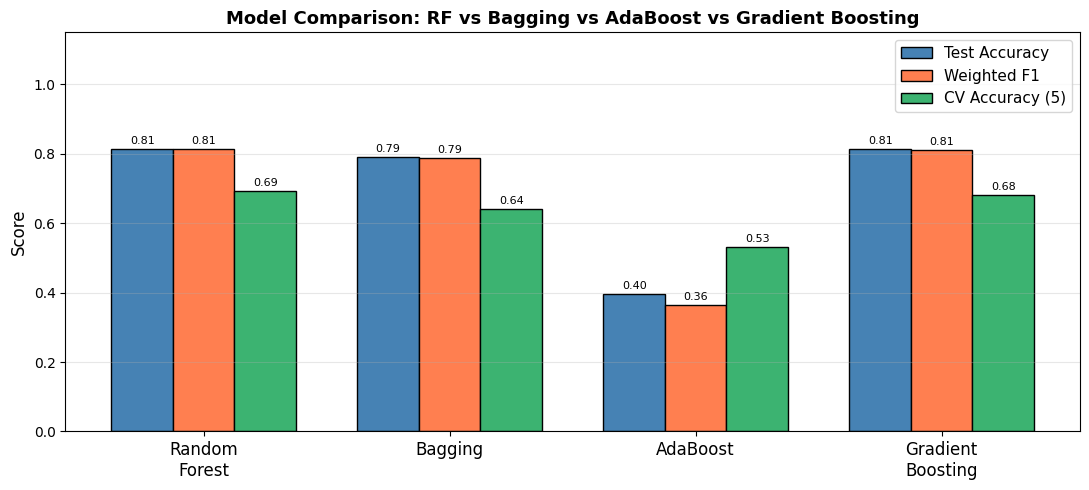

In [39]:
# ── Comparison Bar Chart ──────────────────────────────────────────────────────
preds   = [y_pred_rf, y_pred_bag, y_pred_ada, y_pred_gb]
models  = ['Random\nForest', 'Bagging', 'AdaBoost', 'Gradient\nBoosting']
acc_all = [accuracy_score(y_test, p) for p in preds]
f1_all  = [f1_score(y_test, p, average='weighted') for p in preds]
cv_all  = [cv_rf.mean(), cv_bag.mean(), cv_ada.mean(), cv_gb.mean()]

x, w = np.arange(len(models)), 0.25
fig, ax = plt.subplots(figsize=(11, 5))
b1 = ax.bar(x - w, acc_all, w, label='Test Accuracy',    color='steelblue',      edgecolor='black')
b2 = ax.bar(x,     f1_all,  w, label='Weighted F1',      color='coral',          edgecolor='black')
b3 = ax.bar(x + w, cv_all,  w, label='CV Accuracy (5)',  color='mediumseagreen', edgecolor='black')
ax.set_xticks(x); ax.set_xticklabels(models, fontsize=12)
ax.set_ylim(0, 1.15); ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Comparison: RF vs Bagging vs AdaBoost vs Gradient Boosting',
             fontweight='bold', fontsize=13)
ax.legend(fontsize=11); ax.grid(axis='y', alpha=0.3)
for bar in [*b1, *b2, *b3]:
    ax.annotate(f'{bar.get_height():.2f}',
                (bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.014),
                ha='center', fontsize=8)
plt.tight_layout(); plt.savefig('plot8_model_comparison.png', dpi=130); plt.show()


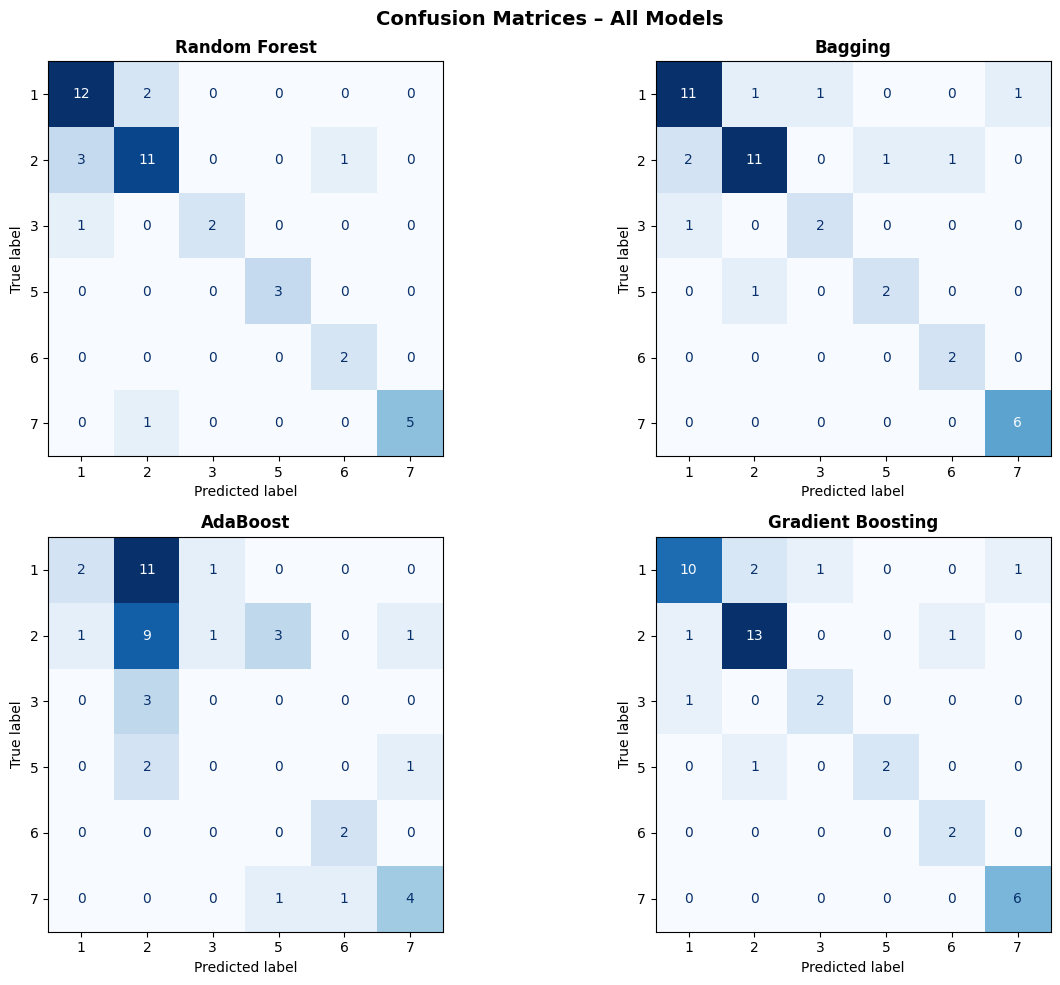

In [40]:
# ── All Confusion Matrices ────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
titles = ['Random Forest', 'Bagging', 'AdaBoost', 'Gradient Boosting']
for ax, pred, title in zip(axes.flat, preds, titles):
    cm = confusion_matrix(y_test, pred, labels=classes)
    ConfusionMatrixDisplay(cm, display_labels=classes).plot(
        ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(title, fontweight='bold', fontsize=12)
plt.suptitle('Confusion Matrices – All Models', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig('plot9_all_confusion.png', dpi=130); plt.show()

In [41]:
# FINAL SUMMARY TABLE

In [42]:
print("\n" + "=" * 65)
print("FINAL MODEL COMPARISON SUMMARY")
print("=" * 65)
summary = pd.DataFrame({
    'Model':     ['Random Forest', 'Bagging', 'AdaBoost', 'Gradient Boosting'],
    'Accuracy':  [round(accuracy_score(y_test, p), 4) for p in preds],
    'Precision': [round(precision_score(y_test, p, average='weighted'), 4) for p in preds],
    'Recall':    [round(recall_score(y_test, p, average='weighted'), 4) for p in preds],
    'F1-Score':  [round(f1_score(y_test, p, average='weighted'), 4) for p in preds],
    'CV Acc':    [round(v, 4) for v in cv_all],
})
print(summary.to_string(index=False))
print(f"\nBest Model by Test Accuracy: {summary.loc[summary['Accuracy'].idxmax(), 'Model']}")



FINAL MODEL COMPARISON SUMMARY
            Model  Accuracy  Precision  Recall  F1-Score  CV Acc
    Random Forest    0.8140     0.8283  0.8140    0.8147  0.6919
          Bagging    0.7907     0.7946  0.7907    0.7889  0.6405
         AdaBoost    0.3953     0.4667  0.3953    0.3638  0.5329
Gradient Boosting    0.8140     0.8216  0.8140    0.8114  0.6823

Best Model by Test Accuracy: Random Forest


In [43]:
# ADDITIONAL NOTES (Written Answers)

In [44]:
print("""
=====================================================================
ADDITIONAL NOTE 1 – Bagging vs Boosting
=====================================================================

BAGGING (Bootstrap Aggregating):
  - Trains multiple models INDEPENDENTLY in parallel on random
    bootstrap subsets of the training data.
  - All base models have equal vote in the final prediction
    (majority vote for classification, average for regression).
  - Goal: Reduce VARIANCE (combats overfitting).
  - Example: Random Forest is a type of Bagging using Decision Trees
    with random feature selection at each split.

BOOSTING:
  - Trains models SEQUENTIALLY. Each new model focuses on the
    errors made by the previous model by assigning higher weights
    to misclassified samples.
  - Final prediction is a weighted combination of all models.
  - Goal: Reduce BIAS (corrects systematic errors).
  - Examples: AdaBoost, Gradient Boosting, XGBoost.

Key Differences:
  ┌──────────────┬──────────────────────────┬──────────────────────────┐
  │              │ BAGGING                  │ BOOSTING                 │
  ├──────────────┼──────────────────────────┼──────────────────────────┤
  │ Training     │ Parallel (independent)   │ Sequential (dependent)   │
  │ Weights      │ Equal for all samples    │ Misclassified get higher │
  │ Reduces      │ Variance (overfitting)   │ Bias (underfitting)      │
  │ Overfitting  │ Low risk                 │ Can overfit w/ noise     │
  │ Speed        │ Fast (parallelisable)    │ Slower (sequential)      │
  └──────────────┴──────────────────────────┴──────────────────────────┘

In this experiment:
  - Random Forest (Bagging) and Gradient Boosting both achieved ~81%
    accuracy, outperforming standalone Bagging (~79%) and AdaBoost.
  - AdaBoost struggled with the multi-class imbalanced glass dataset,
    as it is originally designed for binary classification.

=====================================================================
ADDITIONAL NOTE 2 – Handling Class Imbalance
=====================================================================

The Glass dataset is imbalanced:
  Class 1 (Build Win Float)    : 70 samples  ← majority
  Class 2 (Build Win Non-Float): 76 samples  ← majority
  Class 3 (Vehicle Win Float)  : 17 samples
  Class 5 (Containers)         : 13 samples
  Class 6 (Tableware)          :  9 samples  ← minority
  Class 7 (Headlamps)          : 29 samples

Strategies to Handle Imbalance:

1. CLASS WEIGHTS (used in this assignment):
   - Pass class_weight='balanced' to the classifier.
   - Scikit-learn automatically assigns higher weight to minority
     classes, penalising misclassification of rare classes more.

2. OVERSAMPLING (SMOTE):
   - Synthetic Minority Over-sampling Technique generates synthetic
     samples for minority classes using nearest neighbours.
   - Library: imbalanced-learn → SMOTE()

3. UNDERSAMPLING:
   - Randomly removes samples from majority classes to balance.
   - Risk: loss of useful data from majority classes.

4. EVALUATION METRICS:
   - Use weighted/macro F1-Score and per-class Precision/Recall
     instead of raw Accuracy, as accuracy can be misleadingly high
     when majority classes dominate.
""")



ADDITIONAL NOTE 1 – Bagging vs Boosting

BAGGING (Bootstrap Aggregating):
  - Trains multiple models INDEPENDENTLY in parallel on random
    bootstrap subsets of the training data.
  - All base models have equal vote in the final prediction
    (majority vote for classification, average for regression).
  - Goal: Reduce VARIANCE (combats overfitting).
  - Example: Random Forest is a type of Bagging using Decision Trees
    with random feature selection at each split.

BOOSTING:
  - Trains models SEQUENTIALLY. Each new model focuses on the
    errors made by the previous model by assigning higher weights
    to misclassified samples.
  - Final prediction is a weighted combination of all models.
  - Goal: Reduce BIAS (corrects systematic errors).
  - Examples: AdaBoost, Gradient Boosting, XGBoost.

Key Differences:
  ┌──────────────┬──────────────────────────┬──────────────────────────┐
  │              │ BAGGING                  │ BOOSTING                 │
  ├──────────────┼──────────